## 1. Metadata exploration



In [56]:
# Import packages
import os              
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

In [3]:
eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1,
                             encoding='cp1252')

In [4]:
eji_dictionary

,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (F...,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Bound...,No Value,No Value
3,AFFGEOID,AFFGEOID,Census tract identifier; a concatenation of cu...,No Value,No Value,No Value,No Value,No Value
4,GEOID,GEOID,"11-digit census tract identifier, which is a c...",No Value,No Value,No Value,2020 State FIPS + 2020 County FIPS + 2020 Cens...,Connecticut tracts are using updated 2022 Coun...
...,...,...,...,...,...,...,...,...
165,TWOMORE,No Value,"Adjunct variable - Two or More Races, Not Hisp...",No Value,No Value,2015-2019 Census Bureau American Community Sur...,DP05_0085E,No Value
166,E_TWOMORE,No Value,Adjunct variable - Percentage of Two or More R...,No Value,No Value,2015-2019 Census Bureau American Community Sur...,DP05_0085PE,No Value
167,Tribe_PCT_Tract,No Value,Percent of census tract that intersects with T...,No Value,No Value,The U.S. Census Bureau 2023 American Indian Ar...,No Value,Sum of the geographical intersections of Triba...
168,Tribe_Names,No Value,Concatenation of Tribal land names that inters...,No Value,No Value,The U.S. Census Bureau 2023 American Indian Ar...,No Value,No Value


In [9]:
# Remove leading and trailing spaces
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

# Displays 120 characters per column
pd.set_option('display.max_colwidth', 120)

# Select rows where MODULE is SVM, then select the three columns
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


In [7]:
eji_dictionary.shape

(170, 8)

E_POV200, E_UNINSUR, E_NOINT, E_RENTER, E_GROUPQ

## Polygon intersection

In [8]:
# Read in EJI data
eji_gdb = gpd.read_file('data/EJI_2024_California/EJI_2024_California.gdb/')

# Import fire perimeter
perimeter = gpd.read_file(os.path.join('data','fire25_1.gdb'))

In [16]:
# Match CRS
eji_gdb = eji_gdb.to_crs(perimeter.crs)

assert eji_gdb.crs == perimeter.crs, 'CRS do not match'

In [25]:
# Explore the column names
eji_gdb.columns

Index(['OBJECTID', 'STATEFP', 'COUNTYFP', 'TRACTCE', 'AFFGEOID', 'GEOID',
       'GEOID_2020', 'COUNTY', 'StateDesc', 'STATEABBR',
       ...
       'TWOMORE', 'E_TWOMORE', 'OTHERRACE', 'E_OTHERRACE', 'Tribe_PCT_Tract',
       'Tribe_Names', 'Tribe_Flag', 'Shape_Length', 'Shape_Area', 'geometry'],
      dtype='object', length=174)

In [17]:
# Clean the data
perimeter.columns = perimeter.columns.str.lower()
perimeter.rename(columns={'year_':'year'}, inplace=True)
perimeter.columns

Index(['year', 'state', 'agency', 'unit_id', 'fire_name', 'inc_num', 'irwinid',
       'alarm_date', 'cont_date', 'c_method', 'cause', 'objective',
       'complex_id', 'complex_name', 'comments', 'fire_num', 'shape_length',
       'shape_area', 'globalid', 'geometry'],
      dtype='object')

In [35]:
# Subsect for Palisades Fire
palisades_perimeter = perimeter[(perimeter['fire_name'] == 'PALISADES') & (perimeter['year'] == 2025)]

# Subsect for Eaton Fire
eaton_perimeter = perimeter[(perimeter['fire_name'] == 'EATON') & (perimeter['year'] == 2025)]

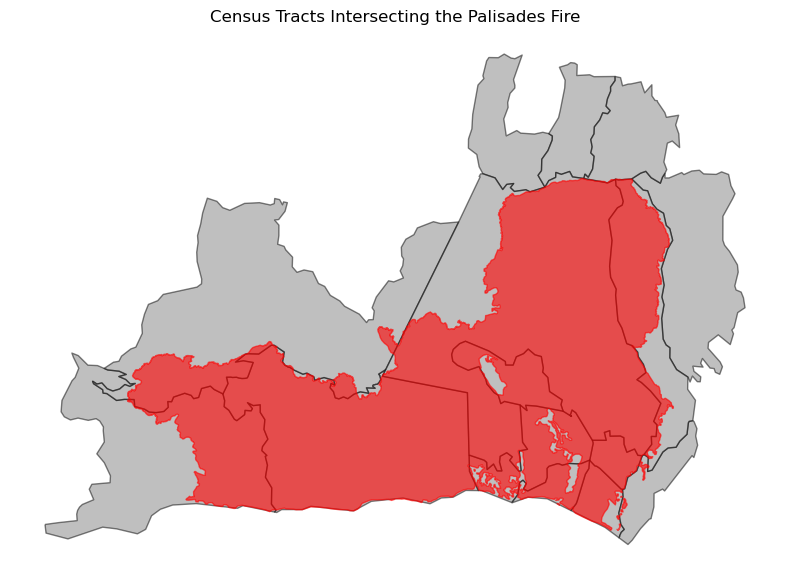

Census tracts intersecting Palisades Fire: 15


In [50]:
# Spatially join EJI data with Palisades
palisades_eji = gpd.sjoin(eji_gdb, palisades_perimeter, how='inner', predicate='intersects')

fig, ax = plt.subplots(1,1,figsize=(8,6))

palisades_eji.plot(ax=ax,
                   color='grey',
                   alpha=0.5,
                   edgecolor='black',
                   label='Census Tracts')

palisades_perimeter.plot(ax=ax,
                         color='red',
                         alpha=0.6,
                         edgecolor='red',
                         label='Palisades Perimeter')

ax.axis('off')
ax.set_title('Census Tracts Intersecting the Palisades Fire')
plt.tight_layout()
plt.show()

print(f'Census tracts intersecting Palisades Fire: {len(palisades_eji)}')

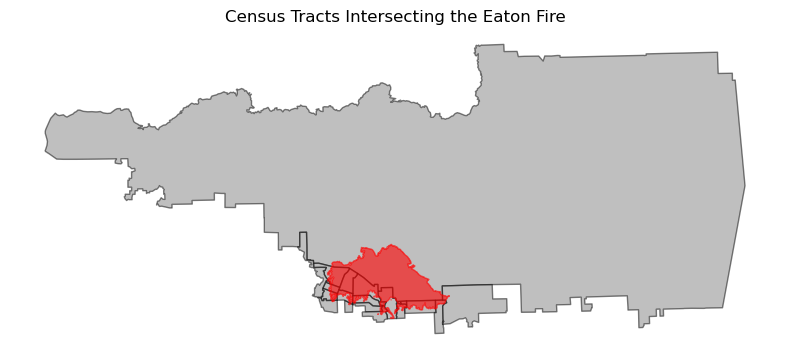

Census tracts intersecting Eaton Fire: 18


In [48]:
# Spatially join EJI data with Eaton
eaton_eji = gpd.sjoin(eji_gdb, eaton_perimeter, how='inner', predicate='intersects')

fig, ax = plt.subplots(figsize=(8,6))

eaton_eji.plot(ax=ax,
                color='grey',
                alpha=0.5,
                edgecolor='black')

eaton_perimeter.plot(ax=ax,
                    color='red',
                    alpha=0.6,
                    edgecolor='red')

ax.set_title('Census Tracts Intersecting the Eaton Fire')
ax.axis('off')
plt.tight_layout()
plt.show()

print(f'Census tracts intersecting Eaton Fire: {len(eaton_eji)}')

## 3. Polygon clipping



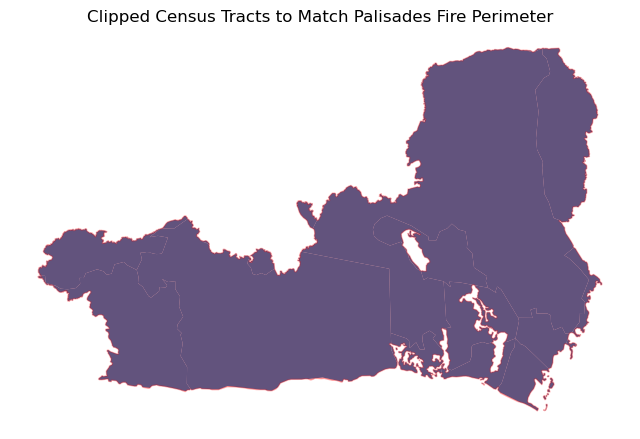

In [55]:
# Clip census tracts to Palisades fire
palisades_census = gpd.clip(palisades_eji, palisades_perimeter)

fig, ax = plt.subplots(figsize=(8,6))

palisades_census.plot(ax=ax)
palisades_perimeter.plot(ax=ax,
                         color='red',
                         alpha=0.3,
                         edgecolor='red',
                         label='Palisades Perimeter')

ax.axis('off')
ax.set_title('Clipped Census Tracts to Match Palisades Fire Perimeter')

plt.show()

## 4. Visualize fire perimeters with a basemap



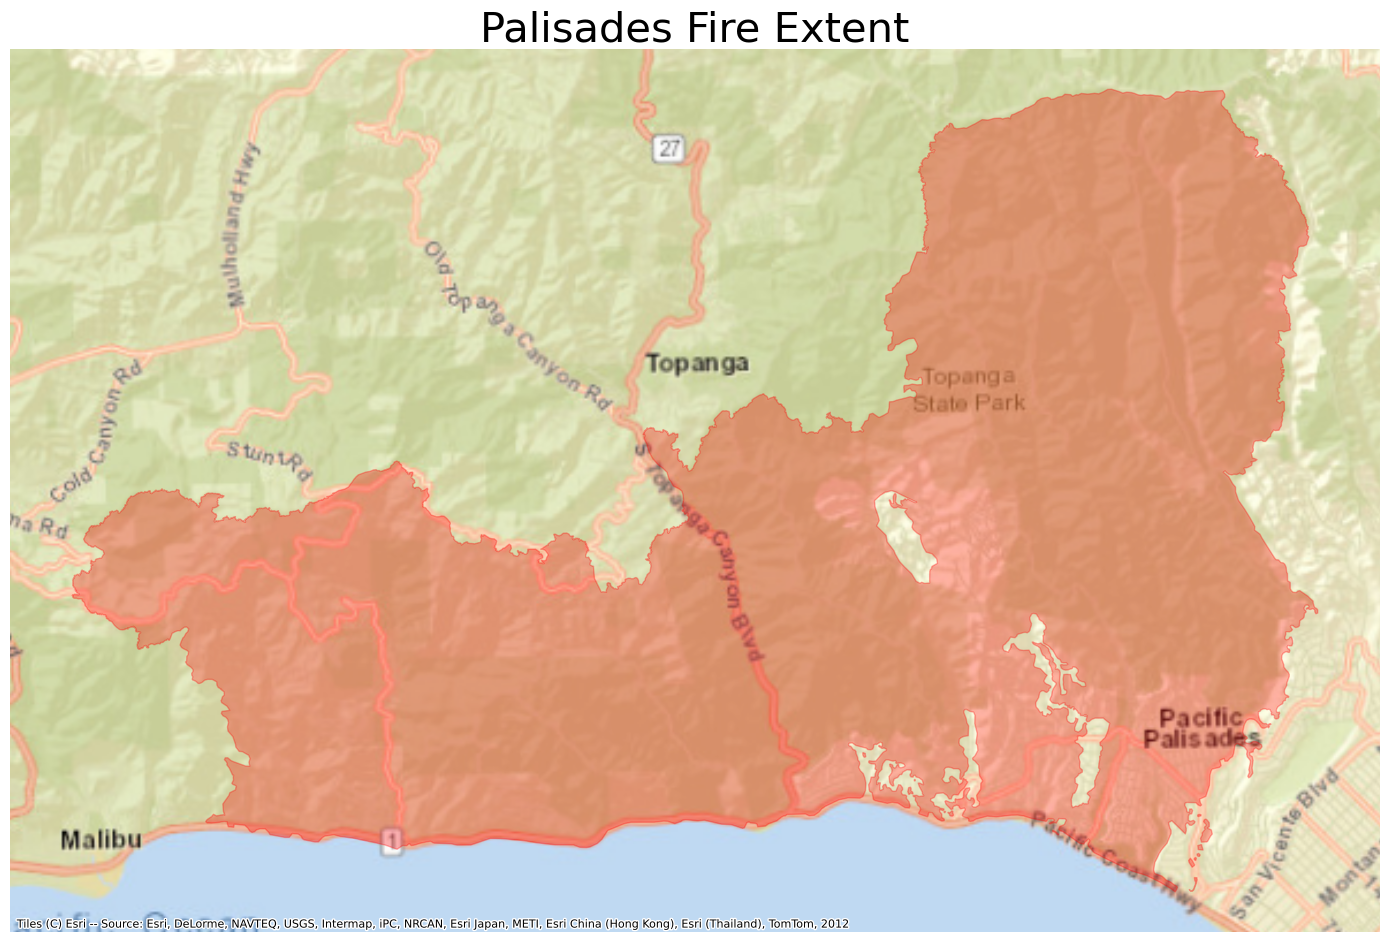

In [61]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# ADD FIRE PERIMETERS: UPDATE FILL TRANSPARENCY AND COLOR
palisades_perimeter.plot(ax=ax,
                         color='red',
                         alpha=0.3,
                         edgecolor='red',
                         label='Palisades Perimeter')

# ADD LEGEND OR ANNOTATION TO IDENTIFY EACH FIRE

# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
ctx.add_basemap(ax, crs=palisades_perimeter.crs, source=ctx.providers.Esri.WorldStreetMap)

# ADD TITLE
ax.set_title('Palisades Fire Extent', fontsize = 30)
ax.axis('off')

plt.tight_layout()
plt.show()